In [238]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import os

In [259]:
def get_topo_edges(fname: str, K):
    cnt_groups = K**2//4 + 1

    if fname == "default":
        return [
            (src_g * cnt_spines + src_sw, dst_g * cnt_spines + dst_sw)
            for h in [K//2]
            for src_g in range(cnt_groups)
            for dst_g in range(src_g + 1, cnt_groups)
            for src_sw, dst_sw in [((dst_g - 1) // h, src_g // h)]
        ]
    
    fname = os.path.join(
        f"/home/vlad/Documents/SublimeMerge/dragonfly-scripts/simulate_dfly_queue_sizes/configs/k_{K}",
        fname
    )
    
    with open(fname) as fin:
        h = K//2

        row_where = [[0 for j in range(cnt_groups)] for i in range(cnt_groups)]
        for group_id, line in enumerate(fin.readlines()):
            v = list(map(int, line.strip().split()))
            for spine_id, spine_content in enumerate([v[i: i+h] for i in range(0, h**2, h)]):
                for spine in spine_content:
                    row_where[group_id][spine] = spine_id

    return [
        (src_g * cnt_spines + src_sw, dst_g * cnt_spines + dst_sw)
        for src_g in range(cnt_groups)
        for dst_g in range(src_g+1, cnt_groups)
        for src_sw, dst_sw in [(row_where[src_g][dst_g], row_where[dst_g][src_g])]
    ]

In [250]:
K = 8
cnt_groups = K**2//4 + 1

r = {4: 5, 6: 10, 8: 100}[K]
node_size = {4: 100, 6: 75, 8: 10}[K]
cent_dist_mul = {4: 1, 6: 1, 8: 4}[K]

alpha = 2 * np.pi / cnt_groups
xy_cent = [r * fn((np.arange(cnt_groups) + 1/3) * alpha) for fn in [np.cos, np.sin]]

cnt_spines = K // 2
dists_from_cent = np.linspace(-cnt_spines / 2, cnt_spines / 2, cnt_spines) * cent_dist_mul

ctg = lambda x: 1 / np.tan(x)
spine_ms = -ctg((np.arange(cnt_groups) + 1/3) * alpha)
spine_bs = r / np.sin((np.arange(cnt_groups) + 1/3) * alpha)

arr_spine_pos = [
    [
        (x_i, y_i)
        for x_c, y_c in [(xy_cent[0][group_id], xy_cent[1][group_id])]
        for d in dists_from_cent
        for delta_x in [d / (m**2 + 1) ** 0.5]
        for x_i in [x_c + delta_x]
        for y_i in [m * x_i + b]
    ]
    for group_id, (m, b) in enumerate(zip(spine_ms, spine_bs))
]

In [264]:
focus_group_id = 0

g = nx.Graph()

g.add_nodes_from(range(cnt_groups * cnt_spines))

# g.add_edges_from(get_topo_edges("default", K))
g.add_edges_from(get_topo_edges("config_2_score_-138.txt", K))

g_pos = {
    spine_id: pos
    for group_id in range(cnt_groups)
    for ind, pos in enumerate(arr_spine_pos[group_id])
    for spine_id in [ind + cnt_spines * group_id]
}

g_colors = [
    "C3" if group_id == focus_group_id else "C0"
    for group_id in range(cnt_groups)
    for i in range(cnt_spines)
]

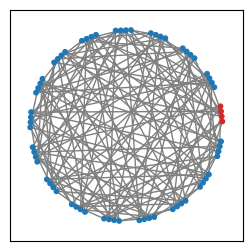

In [265]:
fig, ax = plt.subplots(1, 1, figsize = (3, 3))

nx.draw_networkx(
    g, pos = g_pos, ax = ax,
    node_size = node_size,
    with_labels = False,
    node_color = g_colors,
    edge_color = "gray"
)